# 02 — Diagnostics: is the fit lying to us?

**Status:** Day 3 — first OLS fit and baseline residual plot.
Thursday this notebook grows into the full reading: normality, heteroscedasticity,
leverage, and coefficient sanity.

The one number so far (5-fold CV, out-of-fold):

| spec | CV RMSE (dollars) | CV RMSLE (log) |
|---|---|---|
| v1_full_pipeline | **$77,885** | **0.15453** |

RMSLE 0.15 means a typical prediction is off by about 15% on the log scale.
RMSE in dollars looks alarming ($77k) because a few mansions dominate squared
dollar errors — that's the skew we tamed in the target, showing up in the metric.

## 1. Fit on all of train

The model we diagnose below is fitted on every training house (the CV number
above came from houses the model had never seen; this fit is for inspection).

In [1]:
from house_prices.data import load_train, load_test
from house_prices.features import build_features, align_columns
from house_prices.train import fit_spec

train = load_train()
model, metrics = fit_spec(train)
print(f"CV RMSE ${metrics['rmse']:,.0f}   CV RMSLE {metrics['rmsle']:.5f}")

CV RMSE $77,885   CV RMSLE 0.15453


## 2. Residuals vs fitted — the first lie-detector

**Residual** = what the model predicted minus what actually happened (in log
space, so 0.10 ≈ 10% off). Plotted against the fitted (predicted) value:

- points should scatter **randomly around the zero line** — no patterns
- a **fan shape** (spread grows left→right) = heteroscedasticity → the errors
  aren't equally noisy everywhere; log transforms are the usual fix
- **curvature** = the relationship bends and our straight line misses it →
  feature transforms/interactions
- a few **lonely far-away points** = outliers worth meeting by name

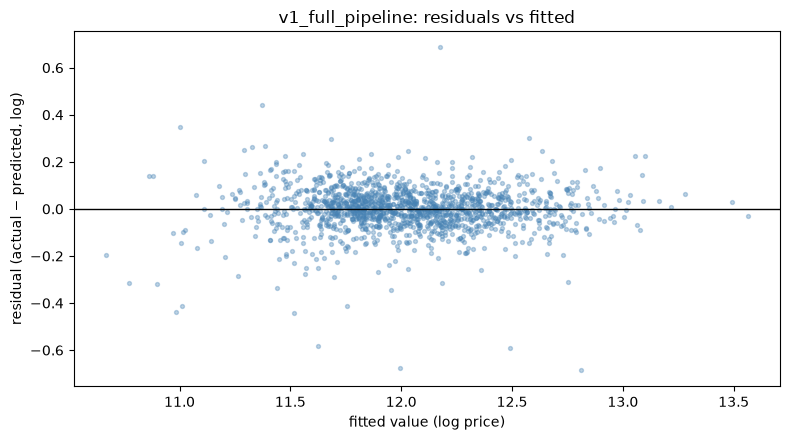

In [2]:
import numpy as np
import matplotlib.pyplot as plt

X, y = build_features(train)
fitted = model.predict(X)
resid = np.asarray(y) - fitted

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(fitted, resid, s=8, alpha=0.35, color="steelblue")
ax.axhline(0, color="black", linewidth=1)
ax.set_xlabel("fitted value (log price)")
ax.set_ylabel("residual (actual − predicted, log)")
ax.set_title("v1_full_pipeline: residuals vs fitted")
plt.tight_layout()

In [3]:
worst = np.argsort(-np.abs(resid))[:10]
train.loc[worst, ["Id", "Neighborhood", "OverallQual", "GrLivArea", "SalePrice"]].assign(
    fitted_log=np.round(fitted[worst], 3), resid=np.round(resid[worst], 3)
).reset_index(drop=True)

,Id,Neighborhood,OverallQual,GrLivArea,SalePrice,fitted_log,resid
0,826,NridgHt,10,2084,385000,12.175,0.686
1,524,Edwards,10,4676,184750,12.813,-0.686
2,633,NWAmes,7,1411,82500,11.995,-0.674
3,1325,Somerst,8,1795,147000,12.491,-0.593
4,463,Sawyer,5,864,62383,11.625,-0.584
5,1433,OldTown,4,968,64500,11.517,-0.442
6,971,NAmes,4,1192,135000,11.371,0.442
7,969,OldTown,3,968,37900,10.982,-0.439
8,31,IDOTRR,4,1317,40000,11.010,-0.413
9,1454,Mitchel,5,1140,84500,11.755,-0.411


## 3. Column alignment — the 253 vs 237 watch item, resolved

One-hot invents a column per category; the test set speaks a smaller dialect.
`align_columns` translates: columns the test set never had become 0, extra
ones are dropped. After alignment both files speak train's 253-column language.

In [4]:
X_train, _ = build_features(load_train())
X_test_raw, _ = build_features(load_test())
X_test = align_columns(X_test_raw, X_train.columns)
print(f"train {X_train.shape}   test {X_test.shape}   aligned: {X_test.shape[1] == X_train.shape[1]}")

train (1460, 254)   test (1459, 254)   aligned: True


## 4. What Thursday checks

- **Shape of the cloud** — fan? curve? (heteroscedasticity / nonlinearity)
- **Q–Q plot** — are residuals roughly normal, as OLS assumes?
- **Leverage & influence** — which houses pull the line hardest (Cook's distance)?
- **Coefficient sanity** — do the biggest coefficients tell a realtor's story,
  or does something have the wrong sign?

Each finding becomes one candidate spec change for Friday.